--- Вправа 1 ---

In [69]:
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
numbers = list(range(10))
print("До set_seed 1:", random.randint(1, 100), random.sample(numbers, len(numbers)))
print("До set_seed 2:", random.randint(1, 100), random.sample(numbers, len(numbers)))

SEED = 42
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()
print("Seed зафіксовано:", SEED)

set_seed()
print("Після set_seed 1:", random.randint(1, 100))
set_seed()
print("Після set_seed 2:", random.randint(1, 100))

print("Без проміжних викликів 1:", random.randint(1, 100))
print("Без проміжних викликів 2:", random.randint(1, 100))

До set_seed 1: 32 [3, 2, 1, 5, 6, 4, 0, 8, 7, 9]
До set_seed 2: 4 [1, 3, 8, 4, 6, 0, 9, 2, 7, 5]
Seed зафіксовано: 42
Після set_seed 1: 82
Після set_seed 2: 82
Без проміжних викликів 1: 15
Без проміжних викликів 2: 4


--- Вправа 2 ---

In [70]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)

if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


Монтуємо Google Drive

In [71]:
import os
from google.colab import drive
drive.mount("/content/drive")

ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)

print("Артефакти зберігаються в:", ARTIFACT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


--- Вправа 3 ---

In [72]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape, zeros_arr.dtype)
print(sevens_arr, sevens_arr.shape, sevens_arr.dtype)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


--- Вправа 4 ---

In [73]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)

[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


--- Вправа 5 ---

In [74]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print("Одинична матриця:")
print(identity)
print("Вимірність identity (ndim):", identity.ndim)

print("\nМасив випадкових чисел:")
print(random_ints)
print("Вимірність random_ints (ndim):", random_ints.ndim)

Одинична матриця:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Вимірність identity (ndim): 2

Масив випадкових чисел:
[[6 3 7]
 [4 6 9]
 [2 6 7]]
Вимірність random_ints (ndim): 2


--- Вправа 6 ---

In [75]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])
mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, "Std:", std)
print("Z-scores:", z_scores)

Середнє: 81.1 Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


--- Вправа 7

In [76]:
arr = np.arange(1, 13)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:", row_sums)
print("Сума по стовпцях:", col_sums)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках: [10 26 42]
Сума по стовпцях: [15 18 21 24]


--- Вправа 8

In [77]:
df = pd.DataFrame({'Студент': ['Олег', 'Анна', 'Іван', 'Марія'], 'score': [85, 92, 78, 95]})
top = df[df['score'] > 80].sort_values(by='score', ascending=False)
print(top)

  Студент  score
3   Марія     95
1    Анна     92
0    Олег     85


--- Вправа 9 ---

In [78]:
df["grade"] = np.where(df["score"] >= 90, "A", np.where(df["score"] >= 75, "B", "C"))
print(df)

  Студент  score grade
0    Олег     85     B
1    Анна     92     A
2    Іван     78     B
3   Марія     95     A


--- Вправа 10 ---

In [79]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t, zeros_t.shape, zeros_t.dtype)
print(sevens_t, sevens_t.shape, sevens_t.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


--- Вправа 11 ---

In [80]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)

tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


--- Вправа 12 ---

In [81]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list, from_list.shape, from_list.dtype, from_list.ndim)
print(random_t, random_t.shape, random_t.dtype, random_t.ndim)

tensor([[1, 2],
        [3, 4]]) torch.Size([2, 2]) torch.int64 2
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]]) torch.Size([3, 3]) torch.float32 2


--- Вправа 13 ---

In [82]:
n = 5.0
x = torch.tensor(n, requires_grad=True)
y = x**2
y.backward()

print("Автоматичний градієнт:", x.grad.item())
print("Аналітичний градієнт:", 2 * n)

Автоматичний градієнт: 10.0
Аналітичний градієнт: 10.0


--- Вправа 14 ---

In [83]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for _ in range(20):
    loss = (x - 3)**2 + 5
    loss.backward()

    with torch.no_grad():
        x -= lr * x.grad

    x.grad.zero_()

print(f"x = {x.item():.4f} (мінімум у x=3)")

x = 2.9654 (мінімум у x=3)


--- Вправа 15 ---

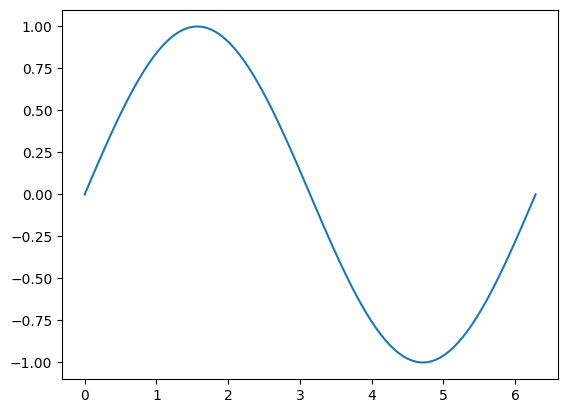

In [84]:
xs = np.linspace(0, 2 * np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()

--- Вправа 16 ---

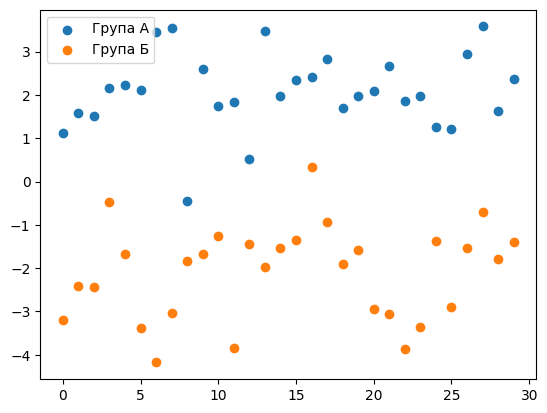

In [85]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.scatter(range(30), group_a, color="C0", label="Група А")
plt.scatter(range(30), group_b, color="C1", label="Група Б")
plt.legend()
plt.show()

--- Вправа 17 ---

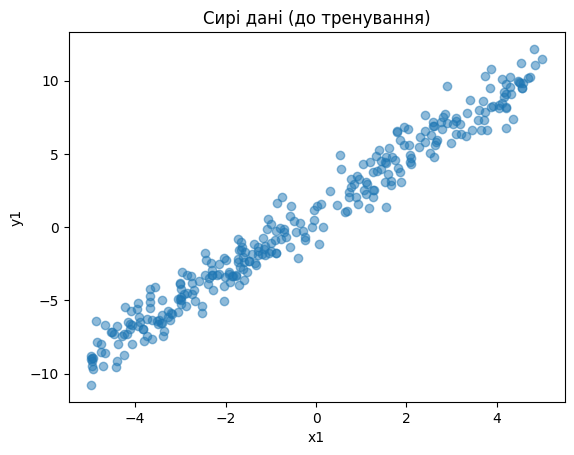

In [86]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300
x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

plt.scatter(x1.numpy(), y1.numpy(), alpha=0.5)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.show()

--- Вправа 18 ---

In [87]:
indices = torch.randperm(TASK1_N)
x1_shuffled = x1[indices]
y1_shuffled = y1[indices]

train_idx = int(0.7 * TASK1_N)
val_idx = train_idx + int(0.15 * TASK1_N)

x_train1, y_train1 = x1_shuffled[:train_idx], y1_shuffled[:train_idx]
x_val1, y_val1 = x1_shuffled[train_idx:val_idx], y1_shuffled[train_idx:val_idx]
x_test1, y_test1 = x1_shuffled[val_idx:], y1_shuffled[val_idx:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


--- Вправа 19

Перша комірка (цикл навчання на 100 епох):

In [88]:
loss_fn = torch.nn.MSELoss()
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)

x_line = torch.linspace(-5, 5, 100).unsqueeze(1) # сітка для візуалізації лінії
snapshots = [] # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward — прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss — наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward — градієнти loss за w і b
    loss.backward()
    # крок оптимізатора — оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
            snapshots.append((epoch, task1_model.weight.item(),
                              task1_model.bias.item(), y_line_pred))
            print(f"epoch {epoch:4d} loss={loss.item():.6f} "
                  f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W}) "
                  f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")

epoch    0 loss=10.796704 w=1.7971 (true 2.0) b=-0.2009 (true 1.0)
epoch   30 loss=1.030498 w=1.9806 (true 2.0) b=1.0221 (true 1.0)
epoch   60 loss=1.026565 w=1.9829 (true 2.0) b=1.0764 (true 1.0)
epoch   90 loss=1.026557 w=1.9830 (true 2.0) b=1.0788 (true 1.0)
epoch   99 loss=1.026557 w=1.9830 (true 2.0) b=1.0789 (true 1.0)


Друга комірка (візуалізація результатів кожні 30 епох):

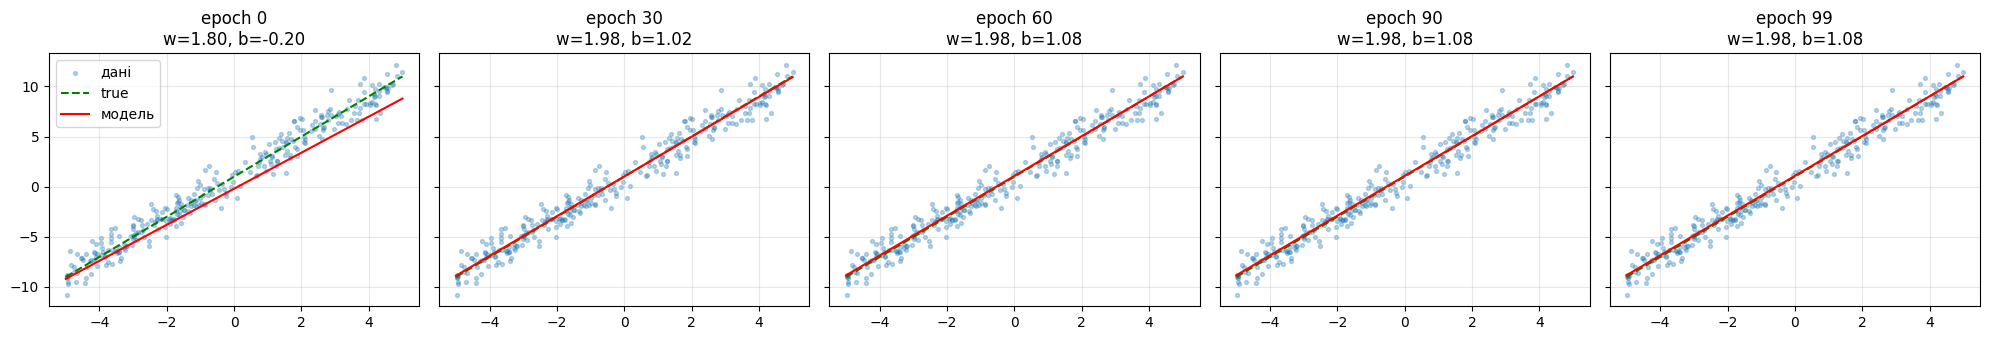

In [89]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B
    fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)

    for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
        ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
        ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
        ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
        ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
        ax.grid(alpha=0.3)

    axes[0].legend()
    plt.tight_layout()
    plt.show()

--- Вправа 20 ---

Сценарій моделює залежність FPS у Counter-Strike 2 від рівня оптимізації графіки для відеокарт AMD.

Параметр b дорівнює 60.0 і позначає базову частоту кадрів на стандартних налаштуваннях. Параметр w дорівнює 1.5 і означає, що кожен відсоток оптимізації додатково дає півтора кадри за секунду.

Ці цифри цілком реалістичні. 60 FPS є типовим початковим показником, а поступове зниження якості текстур лінійно розвантажує відеокарту, що пропорційно підвищує швидкодію гри.

In [90]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

# Генерація даних
N_custom = 200
w_cs = 1.5
b_cs = 60.0

x_cs = torch.empty(N_custom, 1).uniform_(0, 50) # Відсоток оптимізації (0-50%)
noise_cs = 3.0 * torch.randn(N_custom, 1)
y_cs = w_cs * x_cs + b_cs + noise_cs # FPS

# Збереження у CSV
df_cs = pd.DataFrame({"optimization_pct": x_cs.squeeze().numpy(), "fps": y_cs.squeeze().numpy()})
df_cs.to_csv("dataset.csv", index=False)

# Спліт
def prepare_data(x, y):
    idx = torch.randperm(len(x))
    tr, v = int(0.7 * len(x)), int(0.85 * len(x))
    return x[idx][:tr], y[idx][:tr], x[idx][tr:v], y[idx][tr:v], x[idx][v:], y[idx][v:]

x_tr, y_tr, x_v, y_v, x_te, y_te = prepare_data(x_cs, y_cs)

# Функція тренування
def train_linear_model(x_train, y_train, epochs=150, lr=0.001):
    model = nn.Linear(1, 1)
    optimizer = optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    for epoch in range(epochs):
        optimizer.zero_grad()
        pred = model(x_train)
        loss = loss_fn(pred, y_train)
        loss.backward()
        optimizer.step()
    return model

# Тренування
my_model = train_linear_model(x_tr, y_tr)
print(f"Натреновано: w={my_model.weight.item():.2f}, b={my_model.bias.item():.2f}")

# Вправа 21: Збереження
torch.save(my_model.state_dict(), "model.pt")

Натреновано: w=3.19, b=5.06


--- Вправа 22

In [91]:
import gradio as gr

# Завантаження збереженої моделі
loaded_model = nn.Linear(1, 1)
loaded_model.load_state_dict(torch.load("model.pt"))
loaded_model.eval()

def predict_fps(opt_pct):
    with torch.no_grad():
        x_val = torch.tensor([[float(opt_pct)]])
        prediction = loaded_model(x_val).item()
    return f"Очікуваний FPS: {prediction:.1f}"

# Створення інтерфейсу
app = gr.Interface(
    fn=predict_fps,
    inputs=gr.Number(label="Відсоток оптимізації графіки"),
    outputs=gr.Text(label="Прогноз FPS в CS2"),
    title="CS2 FPS Predictor"
)

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d1b1c6b1ca8d0e86f7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
